# Detección de defectos en infraestructuras con RetinaNet v2

**Visión por Computador · Grado en Inteligencia Artificial (USC, 2026/2027)**

Evaluamos RetinaNet v2, preentrenado en COCO, en el conjunto Corrosion-bi3q3 de Roboflow-100. El experimento con mayor resolución interna (960 px) y 20 épocas obtuvo un mAP@[0,50:0,95] de 0,4597 en validación, frente a 0,4319 del baseline. La fusión de la vista original y su volteo horizontal elevó el mAP a 0,4686 con un coste cercano al doble en latencia. En test, el mismo checkpoint obtuvo 0,4277 con una vista y 0,4348 con dos.

In [47]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from IPython.display import display

# Localizar la raíz del proyecto tanto desde la raíz como desde notebooks/.
RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if not (RAIZ / "src").exists():
    raise FileNotFoundError("Abre el notebook desde la raíz del repositorio o desde notebooks/.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.dataset import CorrosionDataset, NOMBRES_CLASES, PARTICIONES
from src.evaluar import cargar_predicciones, _iou_entre_cajas

DIR_RESULTADOS = RAIZ / "results" / "slippage_validation_split"
DIR_FIGURAS = DIR_RESULTADOS / "figuras_retinanet"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

COLORES_CLASE = {
    1: "#1f77b4",  # Slippage
    2: "#d62728",  # corrosion
    3: "#ff7f0e",  # crack
}

print(f"Raíz del proyecto: {RAIZ}")
print(f"Figuras: {DIR_FIGURAS}")
print(f"CUDA disponible: {torch.cuda.is_available()} (no es necesaria para analizar resultados guardados)")


Raíz del proyecto: /home/lucas/IA/Vision/deteccion-corrosion
Figuras: /home/lucas/IA/Vision/deteccion-corrosion/results/slippage_validation_split/figuras_retinanet
CUDA disponible: True (no es necesaria para analizar resultados guardados)


---
## 1. Descripción del dataset (`Corrosion-bi3q3`) y del modelo RetinaNet v2

La partición de validación original carecía de ejemplos de `Slippage`. Para poder evaluar la clase durante el ajuste, trasladamos 20 imágenes de entrenamiento con todas sus anotaciones, según la indicación del profesor. Test conserva su composición original. Todos los experimentos usan el mismo reparto. [Manifiesto de la partición](../configs/particiones/slippage_validation_split.json)

### Particularidades del dataset
- **Resolución:** imágenes de `640 × 640` píxeles. Particiones: `train=820`, `validation=125`, `test=304`; hay imágenes sin objetos anotados (`37 / 5 / 13`).
- **Clases:** `1=Slippage`, `2=corrosion`, `3=crack`; el índice `0` queda reservado y no hay anotaciones de la categoría original `corrosion-0`.
- **Desequilibrio de clases.** En `train` hay 499 anotaciones de `Slippage`, 1.175 de `corrosion` y 1.388 de `crack`. En `validation` hay 49, 165 y 258, respectivamente.
- **Objetos pequeños:** aproximadamente el `85,2 %` de las anotaciones tienen un área inferior a `32²=1024 px²`. Es una posible motivación para probar mayor resolución o anchors adaptados.

### Arquitectura: RetinaNet v2 (`ResNet-50 + FPN v2`)
- Detector **de una etapa (*one-stage*)**: predice clases y cajas directamente sobre una pirámide multiescala de características, sin la fase de propuestas/RoI de Faster R-CNN.
- **Backbone ResNet-50 + FPN** y cabeza de clasificación/regresión; parte de los pesos `RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1` de torchvision.
- **Clasificación por ancla:** utiliza una clasificación sigmoide con pérdida focal, a diferencia del *softmax* de Faster R-CNN. En nuestra adaptación se reservan 4 índices (`0` sin anotaciones, `1..3` defectos) y se generan **9 × 4 = 36 logits** por posición de la cabeza de clasificación.
- Se conservan la cabeza de regresión, GroupNorm y los anchors por defecto en todos los experimentos.

,Partición,Imágenes,Sin objetos,Slippage,corrosion,crack,Total objetos
0,train,820,37,499,1175,1388,3062
1,validation,125,5,49,165,258,472
2,test,304,13,98,317,867,1282


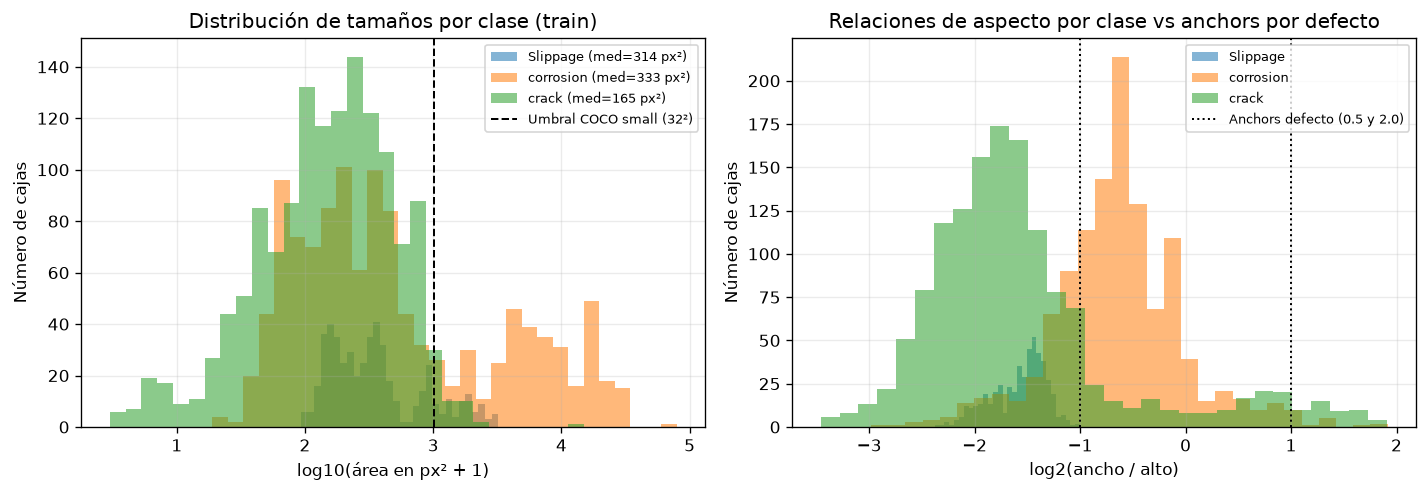

In [48]:
# Análisis cuantitativo de clases, tamaños y relaciones de aspecto (motivación de mejoras)

ruta_dataset = RAIZ / "data" / "corrosion-bi3q3"
if not ruta_dataset.exists():
    print("Dataset no encontrado. Ejecuta: uv run python scripts/descargar_datos.py")
else:
    datos_hf = {particion: CorrosionDataset(particion).datos for particion in PARTICIONES}

    filas_resumen = []
    ratios_por_clase = {nombre: [] for nombre in NOMBRES_CLASES.values()}
    areas_por_clase = {nombre: [] for nombre in NOMBRES_CLASES.values()}

    for particion, datos in datos_hf.items():
        cont = Counter()
        vacias = 0
        for objetos in datos["objects"]:
            cajas = objetos["bbox"]
            cats = objetos["category"]
            if len(cajas) == 0:
                vacias += 1
            cont.update(cats)
            if particion == "train":
                for (x, y, w, h), cat in zip(cajas, cats):
                    nombre = NOMBRES_CLASES[cat]
                    areas_por_clase[nombre].append(w * h)
                    ratios_por_clase[nombre].append(w / max(h, 1e-6))

        filas_resumen.append({
            "Partición": particion,
            "Imágenes": len(datos),
            "Sin objetos": vacias,
            "Slippage": cont.get(1, 0),
            "corrosion": cont.get(2, 0),
            "crack": cont.get(3, 0),
            "Total objetos": sum(cont.values()),
        })

    df_dataset = pd.DataFrame(filas_resumen)
    display(df_dataset)

    # Gráfica de distribución de áreas y relaciones de aspecto por clase en train
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

    for nombre, areas in areas_por_clase.items():
        axes[0].hist(np.log10(np.asarray(areas) + 1), bins=30, alpha=0.55, label=f"{nombre} (med={np.median(areas):.0f} px²)")
    axes[0].axvline(np.log10(32**2), color="black", linestyle="--", linewidth=1.2, label="Umbral COCO small (32²)")
    axes[0].set_xlabel("log10(área en px² + 1)")
    axes[0].set_ylabel("Número de cajas")
    axes[0].set_title("Distribución de tamaños por clase (train)")
    axes[0].legend(fontsize=8)

    for nombre, ratios in ratios_por_clase.items():
        axes[1].hist(np.log2(np.asarray(ratios)), bins=30, alpha=0.55, label=nombre)
    axes[1].axvline(np.log2(0.5), color="black", linestyle=":", linewidth=1.2, label="Anchors defecto (0.5 y 2.0)")
    axes[1].axvline(np.log2(2.0), color="black", linestyle=":", linewidth=1.2)
    axes[1].set_xlabel("log2(ancho / alto)")
    axes[1].set_ylabel("Número de cajas")
    axes[1].set_title("Relaciones de aspecto por clase vs anchors por defecto")
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "01_eda_tamanos_aspecto_retinanet.png", bbox_inches="tight")
    plt.show()


### Análisis de la distribución de los objetos

El dataset presenta un claro predominio de objetos pequeños. La clase `crack` tiene la menor mediana de área (**165 px²**), seguida de `Slippage` (**314 px²**) y `corrosion` (**333 px²**). Una proporción importante de las cajas se encuentra por debajo del umbral de objetos pequeños de COCO (32 × 32 píxeles).

En cuanto a las relaciones de aspecto, las grietas presentan una distribución especialmente alargada, con numerosas cajas cuya relación ancho/alto es inferior a 0,5. Esto podría dificultar su detección con los anchors predeterminados.

La distribución de tamaños motivó el experimento con una mayor resolución interna.

---
## 2. Metodología y resultados del baseline

Partimos de `retinanet_resnet50_fpn_v2` con pesos COCO. Adaptamos la última convolución de clasificación a cuatro índices, dejamos tres bloques entrenables del backbone y fijamos los tamaños mínimo y máximo internos en 800 y 1.333 px.

Entrenamos durante 12 épocas con AdamW (tasa de aprendizaje y *weight decay* de 0,0001), lotes de dos imágenes, acumulación de cuatro pasos y semilla 42. Se utilizó precisión mixta en CUDA. El checkpoint se eligió por mAP@[0,50:0,95] en validación. Los parámetros y comandos de reproducción están en la [configuración del baseline](../configs/retinanet.yaml) y el [README](../README.md#retinanet-v2).

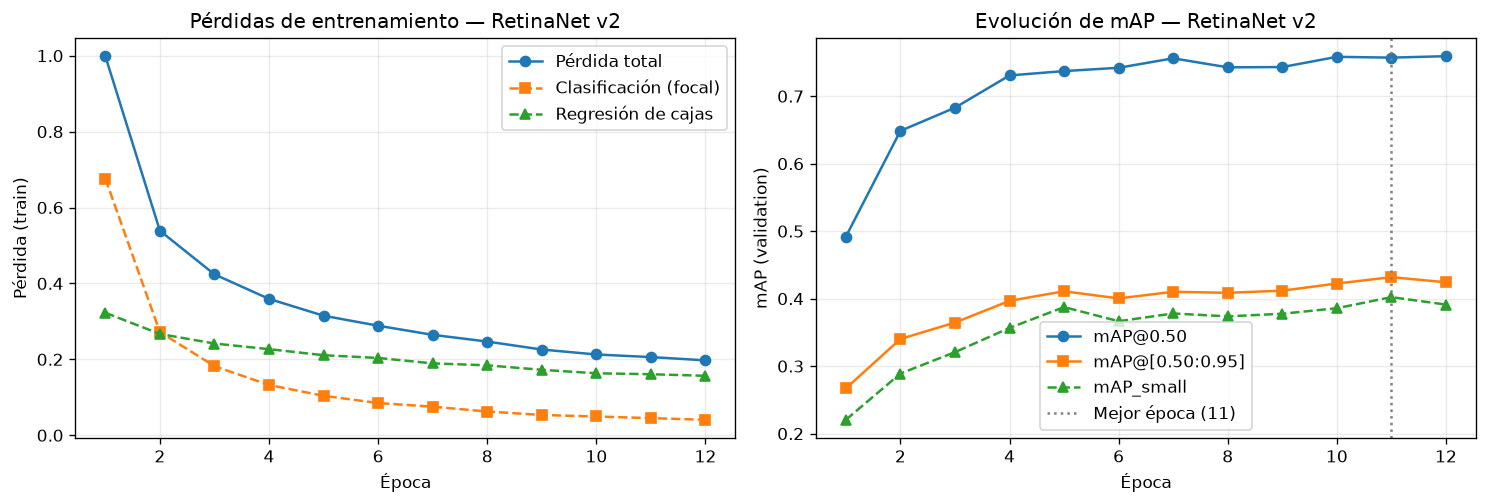

In [49]:
# Registro de experimentos: nombre legible -> carpeta de resultados.
NOMBRE_BASELINE = "Baseline (RetinaNet v2)"
NOMBRE_E2_20 = "E2: 960 px · 20 épocas"
EXPERIMENTOS = {
    NOMBRE_BASELINE: {
        "dir": DIR_RESULTADOS / "retinanet",
        "categoria": "Baseline",
        "hipotesis": "RetinaNet v2 COCO_V1, AdamW, 800 px y anchors por defecto.",
    },
    "E1: Aumento de datos": {
        "dir": DIR_RESULTADOS / "retinanet_exp01_aumentos",
        "categoria": "Aumentos",
        "hipotesis": "Volteos y variaciones de color para mejorar la generalización.",
    },
    "E2: 960 px · 12 épocas": {
        "dir": DIR_RESULTADOS / "retinanet_exp02_resolucion",
        "categoria": "Resolución",
        "hipotesis": "Evaluar mayor resolución interna para objetos pequeños.",
    },
    NOMBRE_E2_20: {
        "dir": DIR_RESULTADOS / "retinanet_exp02_resolucion_20ep",
        "categoria": "Resolución",
        "hipotesis": "Comprobar si más épocas mejoran el mAP a 960 px.",
    },
    "E3: SGD con momentum": {
        "dir": DIR_RESULTADOS / "retinanet_exp03_sgd",
        "categoria": "Optimización",
        "hipotesis": "Comparar SGD + momentum frente a AdamW.",
    },
}

COLORES_EXPERIMENTO = dict(zip(EXPERIMENTOS, plt.get_cmap("tab10").colors))


def leer_json(ruta: Path) -> dict | list | None:
    if not ruta.exists():
        return None
    with ruta.open(encoding="utf-8") as archivo:
        return json.load(archivo)


def cargar_historial_experimento(dir_exp: Path) -> list[dict] | None:
    datos = leer_json(dir_exp / "historial.json")
    return datos if isinstance(datos, list) else None


def cargar_metricas_experimento(dir_exp: Path, particion: str = "validation") -> dict | None:
    """Carga las métricas guardadas o, en validación, el mejor registro del historial."""
    rutas = [dir_exp / f"metricas_{particion}.json"]
    if particion == "test":
        rutas.insert(0, dir_exp / "metricas_test_final.json")
    for ruta in rutas:
        datos = leer_json(ruta)
        if isinstance(datos, dict):
            metricas = datos.get(particion, datos)
            if isinstance(metricas, dict) and "map" in metricas:
                return metricas
    if particion == "validation":
        historial = cargar_historial_experimento(dir_exp)
        if historial:
            registros = [h.get("metricas_val", {}) for h in historial]
            registros = [m for m in registros if isinstance(m, dict) and "map" in m]
            if registros:
                return max(registros, key=lambda m: m["map"])
    return None


# Curvas de entrenamiento del baseline: claves propias de RetinaNet.
hist_base = cargar_historial_experimento(EXPERIMENTOS[NOMBRE_BASELINE]["dir"])
if hist_base:
    epocas = [h["epoca"] for h in hist_base]
    perdida_total = [h["perdidas_train"].get("total", np.nan) for h in hist_base]
    perdida_cls = [h["perdidas_train"].get("classification", np.nan) for h in hist_base]
    perdida_cajas = [h["perdidas_train"].get("bbox_regression", np.nan) for h in hist_base]
    val_map = [h["metricas_val"]["map"] for h in hist_base]
    val_map50 = [h["metricas_val"]["map_50"] for h in hist_base]
    val_small = [h["metricas_val"].get("map_small", np.nan) for h in hist_base]

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
    axes[0].plot(epocas, perdida_total, marker="o", label="Pérdida total")
    axes[0].plot(epocas, perdida_cls, marker="s", linestyle="--", label="Clasificación (focal)")
    axes[0].plot(epocas, perdida_cajas, marker="^", linestyle="--", label="Regresión de cajas")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Pérdida (train)")
    axes[0].set_title("Pérdidas de entrenamiento — RetinaNet v2")
    axes[0].legend()

    axes[1].plot(epocas, val_map50, marker="o", label="mAP@0.50")
    axes[1].plot(epocas, val_map, marker="s", label="mAP@[0.50:0.95]")
    axes[1].plot(epocas, val_small, marker="^", linestyle="--", label="mAP_small")
    mejor_idx = int(np.nanargmax(val_map))
    axes[1].axvline(epocas[mejor_idx], color="gray", linestyle=":", label=f"Mejor época ({epocas[mejor_idx]})")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("mAP (validation)")
    axes[1].set_title("Evolución de mAP — RetinaNet v2")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "02_baseline_curvas_entrenamiento.png", bbox_inches="tight")
    plt.show()
else:
    print("Aún no existe results/slippage_validation_split/retinanet/historial.json. Ejecuta primero el baseline.")

### Evolución del baseline

La pérdida de entrenamiento baja de 1,00 a 0,20 a lo largo de las 12 épocas. El mAP de validación mejora sobre todo en las primeras y alcanza su máximo en la época 11 (0,4318 en el historial). La pérdida sigue cayendo hasta la última época mientras que el mAP de validación apenas cambia.

=== RetinaNet baseline: validación ===
mAP@[0.50:0.95]: 0.4319 | mAP@0.50: 0.7572
mAP_small: 0.4023
Latencia: 26.84 ms/img (37.26 FPS)


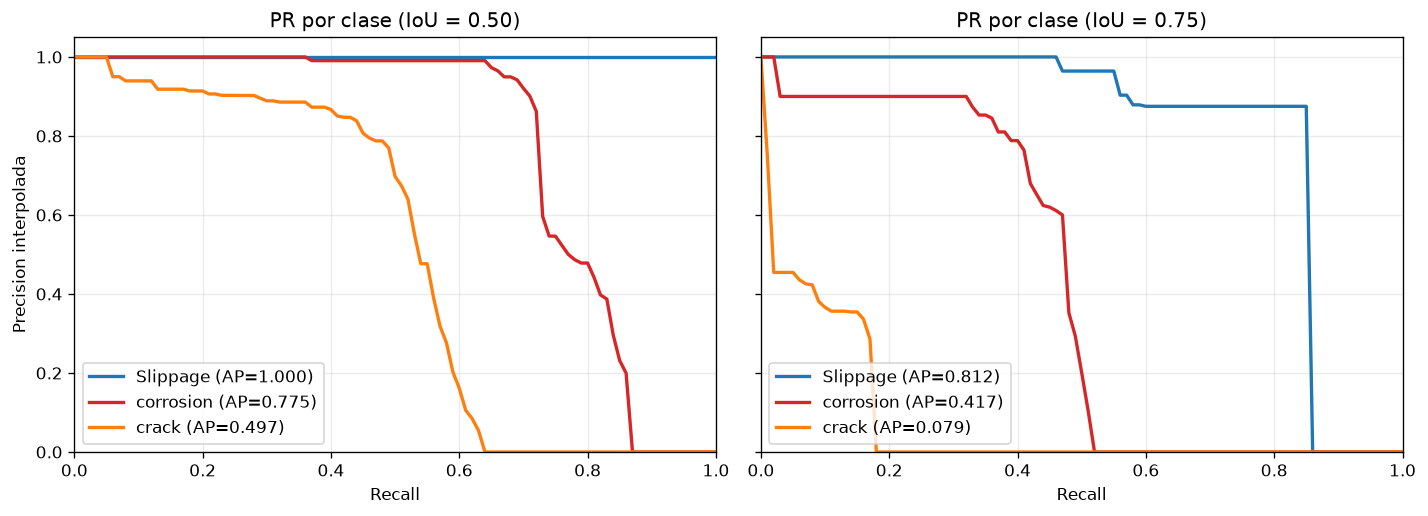

In [50]:
# Curvas precisión-recall y resumen del baseline en VALIDACIÓN.
met_base = cargar_metricas_experimento(EXPERIMENTOS[NOMBRE_BASELINE]["dir"], "validation")

if met_base:
    print("=== RetinaNet baseline: validación ===")
    print(f"mAP@[0.50:0.95]: {met_base['map']:.4f} | mAP@0.50: {met_base['map_50']:.4f}")
    if "map_small" in met_base:
        print(f"mAP_small: {met_base['map_small']:.4f}")
    if "tiempos" in met_base:
        t = met_base["tiempos"]
        print(f"Latencia: {t['ms_por_imagen']:.2f} ms/img ({t['fps']:.2f} FPS)")

    if "curvas_pr_50" in met_base:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
        for ax, clave, titulo in [
            (axes[0], "curvas_pr_50", "PR por clase (IoU = 0.50)"),
            (axes[1], "curvas_pr_75", "PR por clase (IoU = 0.75)"),
        ]:
            curvas = met_base.get(clave, {})
            for id_c, nombre in NOMBRES_CLASES.items():
                c = curvas.get(nombre)
                if c and c.get("n_gt", 0) > 0 and len(c.get("recall", [])) > 0:
                    ax.plot(c["recall"], c["precision_interp"], linewidth=2,
                            color=COLORES_CLASE[id_c], label=f"{nombre} (AP={c['ap']:.3f})")
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.05)
            ax.set_xlabel("Recall")
            ax.set_title(titulo)
            if ax.lines:
                ax.legend(loc="lower left")
        axes[0].set_ylabel("Precision interpolada")
        plt.tight_layout()
        plt.savefig(DIR_FIGURAS / "03_baseline_curvas_pr_validation.png", bbox_inches="tight")
        plt.show()
    else:
        print("Para obtener curvas PR y tiempos, evalúa el checkpoint sobre validation:")
        print("uv run --locked python -m src.evaluar --checkpoint results/slippage_validation_split/retinanet/mejor_modelo.pth "
              "--particion validation --guardar results/slippage_validation_split/retinanet/metricas_validation.json "
              "--guardar-preds results/slippage_validation_split/retinanet/predicciones_validation.json")
else:
    print("Todavía no se encontraron métricas de validación para RetinaNet.")


### Análisis de las curvas precisión-recall

Las curvas PR muestran diferencias importantes en el rendimiento de RetinaNet según la clase y el umbral de IoU utilizado.

Con **IoU = 0,50**, `Slippage` alcanza un AP de **1,000**, manteniendo una precisión prácticamente perfecta. `corrosion` obtiene un AP de **0,775**, aunque su precisión disminuye al aumentar el recall. Por su parte, `crack` presenta el peor rendimiento (AP = **0,497**), con una caída pronunciada de precisión a partir de un recall cercano a 0,5.

Al aumentar el umbral a **IoU = 0,75**, los resultados empeoran considerablemente:

- **Slippage:** AP = 0,812.
- **corrosion:** AP = 0,417.
- **crack:** AP = 0,079.

Esta caída es especialmente acusada en `crack`, lo que indica que el modelo tiene dificultades para localizar con precisión las grietas, incluso cuando consigue detectarlas con un criterio de IoU menos exigente.

La diferencia entre ambos IoU es mayor para `crack`. Su tamaño y sus relaciones de aspecto alargadas podrían dificultar el ajuste de las cajas.

El resultado de `Slippage` debe interpretarse con cautela, ya que únicamente existen 49 anotaciones de esta clase en validación.

---
## 3. Diseño de los experimentos

E1, E2 y E3 se compararon primero con el baseline de 12 épocas, con la misma inicialización, el mismo reparto y la semilla 42. E2 a 960 px fue la única configuración cuyo mejor checkpoint se obtuvo en la última época. Por eso repetimos esa configuración desde los pesos COCO durante 20 épocas, con el calendario coseno ajustado a la nueva duración.

| Estrategia | Cambio evaluado | Hipótesis |
|---|---|---|
| **E1 · Aumento de datos** | Sobre el volteo horizontal del baseline se añaden volteo vertical, recortes con zoom y variaciones de color. | El conjunto de aumentos puede mejorar la generalización ante cambios de orientación, escala e iluminación. |
| **E2 · Mayor resolución** | Se aumenta el tamaño mínimo interno de 800 a 960 px. | Una entrada mayor puede facilitar la localización de defectos pequeños. |
| **E2 · 20 épocas** | Se repite E2 desde los pesos COCO con 20 épocas. El scheduler coseno se ajusta a esa duración. | Un entrenamiento más largo podría mejorar el mAP a 960 px. |
| **E3 · SGD** | Se usa SGD con momentum de 0,9 y una tasa de aprendizaje de 0,005. Se mantiene el scheduler coseno. | Esta configuración de optimización podría mejorar la generalización frente a AdamW. |
| **TTA con WBF** | El checkpoint seleccionado procesa la imagen original y su volteo horizontal. Se fusionan ambas predicciones durante la inferencia. | La segunda vista puede mejorar la detección y la localización. |

En cada entrenamiento conservamos el checkpoint con mayor mAP@[0,50:0,95] en validación. La configuración de inferencia también se eligió en validación antes de evaluarla en test.

---
## 4. Comparación de los entrenamientos en validación

El baseline, E1, E2 a 960 px y E3 forman la **comparación a 12 épocas**. E2 a 20 épocas se incluye como ampliación posterior. Se entrenó desde los pesos COCO con un calendario coseno ajustado a 20 épocas, así que su presupuesto de entrenamiento es distinto.

Las curvas muestran la pérdida total de entrenamiento y el mAP de validación por época. El punto marcado en cada serie indica el checkpoint elegido. La tabla usa una evaluación posterior de esos checkpoints con una sola vista por imagen. F1@0,50 se toma del análisis de errores guardado, con IoU y confianza mínimos de 0,50. El símbolo «—» indica un valor ausente.

La frontera de Pareto destaca los modelos para los que ninguna otra configuración logra un mAP al menos igual con una latencia al menos tan baja y una mejora estricta en alguna de las dos métricas. Los tiempos del gráfico miden el pase del modelo en lotes de cuatro imágenes, excluyendo el primer lote. La comparación con TTA se presenta en la sección 5, con mediciones imagen a imagen que incluyen transferencias y fusión.

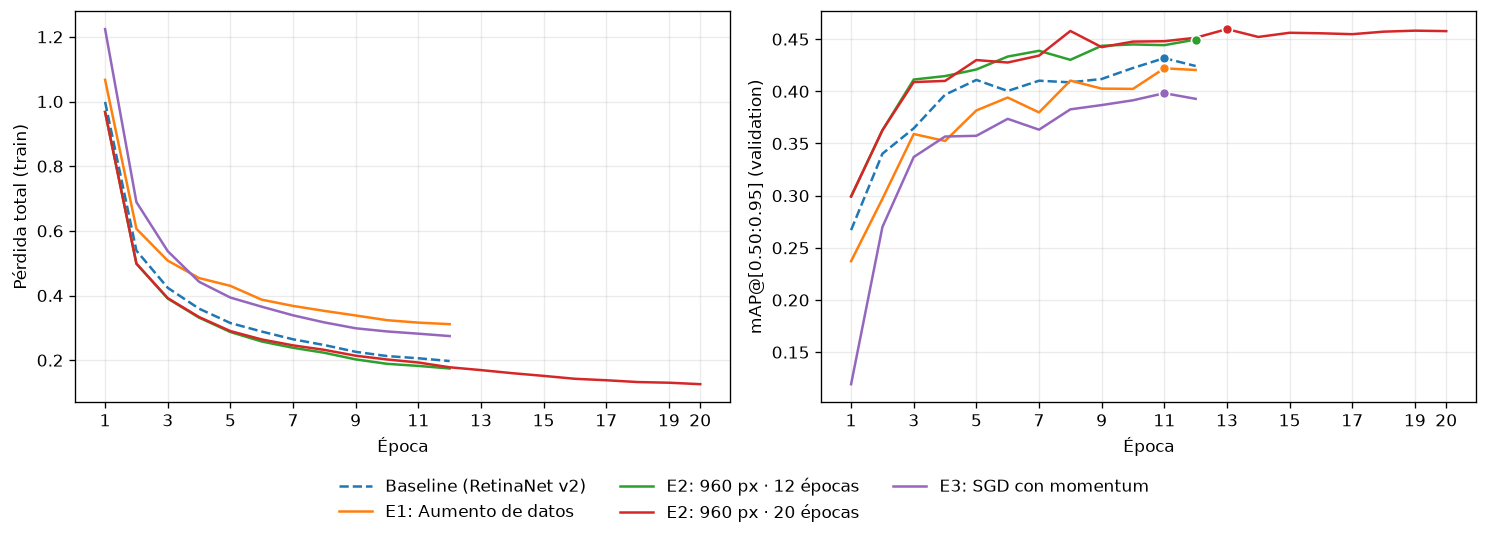

In [56]:
historiales = {
    nombre: historial
    for nombre, meta in EXPERIMENTOS.items()
    if (historial := cargar_historial_experimento(meta["dir"]))
}

if historiales:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), sharex=True)

    for nombre, historial in historiales.items():
        epocas = [registro["epoca"] for registro in historial]
        perdidas = [registro["perdidas_train"]["total"] for registro in historial]
        m_ap = [registro["metricas_val"]["map"] for registro in historial]
        mejor = int(np.argmax(m_ap))
        color = COLORES_EXPERIMENTO[nombre]
        estilo = "--" if nombre == NOMBRE_BASELINE else "-"
        axes[0].plot(epocas, perdidas, linestyle=estilo, color=color, label=nombre)
        axes[1].plot(epocas, m_ap, linestyle=estilo, color=color)
        axes[1].scatter(epocas[mejor], m_ap[mejor], color=color, edgecolors="white", zorder=3)

    axes[0].set_ylabel("Pérdida total (train)")
    axes[1].set_ylabel("mAP@[0.50:0.95] (validation)")
    ultima_epoca = max(historial[-1]["epoca"] for historial in historiales.values())
    axes[1].set_xticks([*range(1, ultima_epoca, 2), ultima_epoca])
    for ax in axes:
        ax.set_xlabel("Época")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(3, len(labels)), frameon=False)
    fig.tight_layout(rect=(0, 0.11, 1, 1))
    fig.savefig(DIR_FIGURAS / "09_curvas_entrenamiento_experimentos.png", bbox_inches="tight")
    plt.show()
else:
    print("No hay historiales de entrenamiento disponibles.")

In [60]:
filas_comp = []
metricas_por_exp = {}

for nombre, meta in EXPERIMENTOS.items():
    m = cargar_metricas_experimento(meta["dir"], "validation")
    if not m:
        continue
    metricas_por_exp[nombre] = m
    ap_clase = m.get("map_por_clase", {})
    tiempos = m.get("tiempos", {})
    filas_comp.append({
        "Experimento": nombre,
        "Categoría": meta["categoria"],
        "mAP@0.50:0.95": m.get("map", np.nan),
        "mAP@0.50": m.get("map_50", np.nan),
        "mAP@0.75": m.get("map_75", np.nan),
        "mAP_small": m.get("map_small", np.nan),
        "AP Slippage": ap_clase.get("Slippage", np.nan),
        "AP corrosion": ap_clase.get("corrosion", np.nan),
        "AP crack": ap_clase.get("crack", np.nan),
        "F1@0.5": (m.get("analisis_errores_05") or {}).get("f1", np.nan),
        "ms/img": tiempos.get("ms_por_imagen", np.nan),
        "FPS": tiempos.get("fps", np.nan),
    })

if filas_comp:
    df_comp = pd.DataFrame(filas_comp)
    base = metricas_por_exp.get(NOMBRE_BASELINE)
    referencia = base["map"] if base is not None else np.nan
    df_comp.insert(3, "ΔmAP vs Base", df_comp["mAP@0.50:0.95"] - referencia)
    print("Comparativa en validación:")
    display(df_comp.style.format({"ms/img": "{:.2f}", "FPS": "{:.2f}"}, precision=4, na_rep="—"))

    fig, ax = plt.subplots(figsize=(11, max(3.5, 0.7 * len(df_comp) + 1.5)))
    y = np.arange(len(df_comp))
    alto = 0.26
    ax.barh(y - alto, df_comp["mAP@0.50"], height=alto, label="mAP@0.50")
    ax.barh(y, df_comp["mAP@0.50:0.95"], height=alto, label="mAP@[0.50:0.95]")
    ax.barh(y + alto, df_comp["mAP_small"], height=alto, label="mAP_small")
    ax.set_yticks(y)
    ax.set_yticklabels(df_comp["Experimento"])
    ax.invert_yaxis()
    ax.set_xlabel("Puntuación COCO (validation)")
    ax.set_title("RetinaNet v2 — estrategias de mejora en validación")
    ax.legend()
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "04_comparativa_validacion.png", bbox_inches="tight")
    plt.show()

    col_map = "mAP@0.50:0.95"
    df_lat = df_comp.dropna(subset=["ms/img", col_map])
    if not df_lat.empty:
        # A igual latencia, solo el mayor mAP puede pertenecer a la frontera.
        puntos = df_lat.sort_values(["ms/img", col_map], ascending=[True, False])
        puntos = puntos.drop_duplicates(subset="ms/img")
        maximo_previo = puntos[col_map].cummax().shift(fill_value=-np.inf)
        pareto = puntos[puntos[col_map] > maximo_previo]

        fig, ax = plt.subplots(figsize=(10.5, 4.5), layout="constrained")
        ax.plot(pareto["ms/img"], pareto[col_map], "--", color="0.35", zorder=2,
                label="Frontera de Pareto")
        for _, fila in df_lat.iterrows():
            nombre = fila["Experimento"]
            ax.scatter(fila["ms/img"], fila[col_map], s=85, color=COLORES_EXPERIMENTO[nombre],
                       label=nombre, zorder=3)
        ax.scatter(pareto["ms/img"], pareto[col_map], s=145, facecolors="none",
                   edgecolors="0.35", zorder=4)
        ax.set_xlabel("Tiempo de inferencia (ms/imagen, lote de 4)")
        ax.set_ylabel("mAP@[0.50:0.95] (validation)")
        ax.set_title("Precisión frente a latencia — RetinaNet v2")
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
        fig.savefig(DIR_FIGURAS / "05_tradeoff_latencia_validation.png", bbox_inches="tight")
        plt.show()
else:
    print("Aún no hay métricas de validación. Ejecuta el baseline y vuelve a abrir el notebook.")

Comparativa en validación:


<Figure size 1320x600 with 1 Axes>

<Figure size 1260x540 with 1 Axes>

### Efecto de cada estrategia

- **E1 · Aumentos.** El AP de `corrosion` sube de 0,4464 a 0,4805. El AP de las otras dos clases cae y el mAP global pasa de 0,4319 a 0,4221. El resultado corresponde al conjunto de transformaciones evaluado.
- **E2 · Resolución.** A 960 px y 12 épocas, el mAP sube a 0,4497 y el de objetos pequeños pasa de 0,4023 a 0,4263. La latencia medida aumenta de 26,84 a 35,81 ms por imagen.
- **E2 · 20 épocas.** El mejor checkpoint fue el de la época 13. Alcanzó 0,4597 de mAP y 0,4376 en objetos pequeños, aproximadamente 1,00 y 1,13 puntos más que E2 a 12 épocas. El mAP@0,75 pasó de 0,4360 en el baseline a 0,4565 con 12 épocas a 960 px y a 0,4766 con 20 épocas.
- **E3 · SGD.** La configuración probada queda en 0,3985 de mAP, 3,34 puntos por debajo del baseline con AdamW.

Mejor configuración en validation: E2: 960 px · 20 épocas (mAP=0.4597)


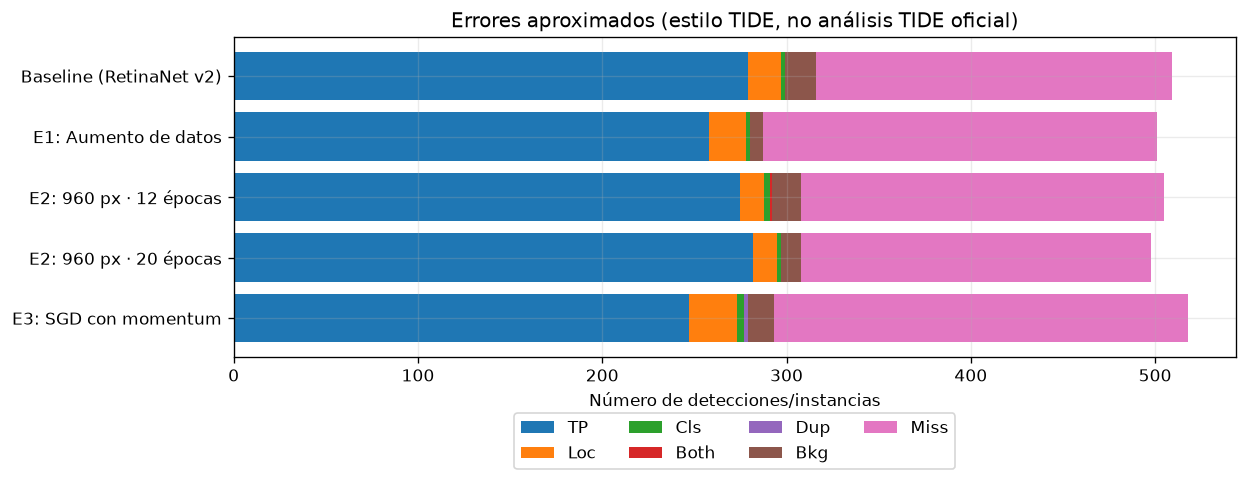

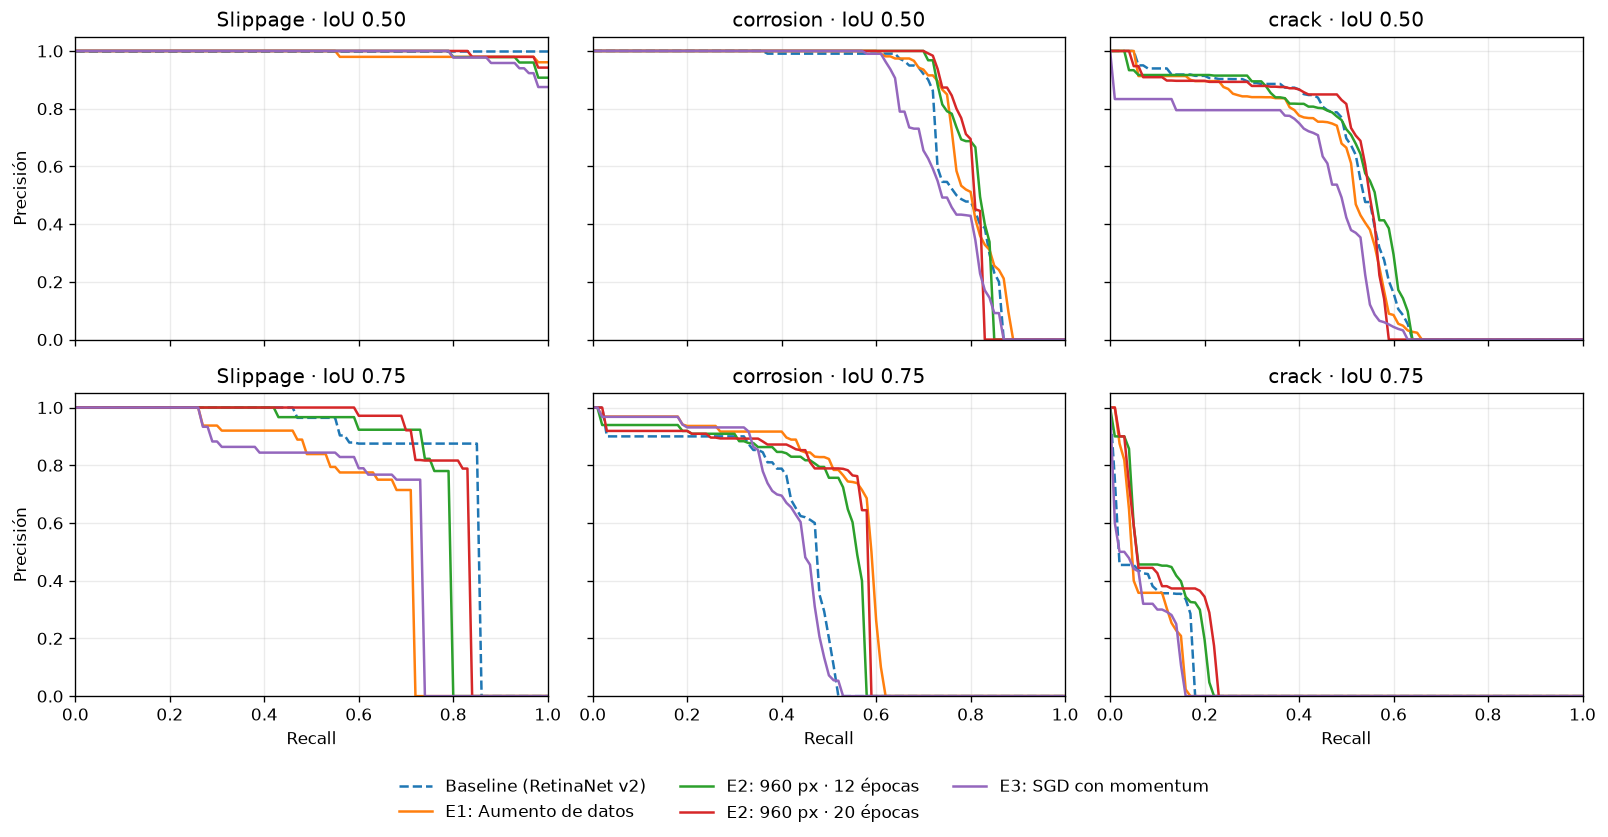

In [58]:
# Curvas PR y desglose de errores de los checkpoints elegidos en validación.
if metricas_por_exp:
    nombre_mejor = max(metricas_por_exp, key=lambda k: metricas_por_exp[k].get("map", -1))
    print(f"Mejor configuración en validation: {nombre_mejor} "
          f"(mAP={metricas_por_exp[nombre_mejor]['map']:.4f})")

    claves_err = ["TP", "Loc", "Cls", "Both", "Dup", "Bkg", "Miss"]
    exps_con_err = [n for n, m in metricas_por_exp.items() if "analisis_errores_05" in m]
    if exps_con_err:
        fig, ax = plt.subplots(figsize=(10.5, max(3.5, 0.6 * len(exps_con_err) + 1.2)))
        y = np.arange(len(exps_con_err))
        izquierda = np.zeros(len(exps_con_err))
        for clave in claves_err:
            valores = np.array([metricas_por_exp[n]["analisis_errores_05"].get(clave, 0)
                                for n in exps_con_err])
            ax.barh(y, valores, left=izquierda, label=clave)
            izquierda += valores
        ax.set_yticks(y)
        ax.set_yticklabels(exps_con_err)
        ax.invert_yaxis()
        ax.set_xlabel("Número de detecciones/instancias")
        ax.set_title("Errores aproximados (estilo TIDE, no análisis TIDE oficial)")
        ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
        plt.tight_layout()
        plt.savefig(DIR_FIGURAS / "06_errores_validacion.png", bbox_inches="tight")
        plt.show()
    else:
        print("Para comparar tipos de errores, guarda metricas_validation.json con src.evaluar.")

    curvas_por_iou = {
        iou: {
            experimento: metricas[clave]
            for experimento, metricas in metricas_por_exp.items()
            if clave in metricas
        }
        for iou, clave in [("0.50", "curvas_pr_50"), ("0.75", "curvas_pr_75")]
    }

    if any(curvas_por_iou.values()):
        clases = list(NOMBRES_CLASES.values())
        fig, axes = plt.subplots(2, len(clases), figsize=(13.5, 7), sharex=True, sharey=True)
        leyenda = {}

        for fila, (iou, curvas) in enumerate(curvas_por_iou.items()):
            for ax, clase in zip(axes[fila], clases):
                for experimento, por_clase in curvas.items():
                    curva = por_clase.get(clase, {})
                    if curva.get("n_gt", 0) > 0 and curva.get("recall"):
                        estilo = "--" if experimento == NOMBRE_BASELINE else "-"
                        linea, = ax.plot(
                            curva["recall"], curva["precision_interp"],
                            linestyle=estilo, color=COLORES_EXPERIMENTO[experimento],
                        )
                        leyenda[experimento] = linea
                ax.set_title(f"{clase} · IoU {iou}")
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1.05)
            axes[fila, 0].set_ylabel("Precisión")

        for ax in axes[-1]:
            ax.set_xlabel("Recall")
        etiquetas = [nombre for nombre in EXPERIMENTOS if nombre in leyenda]
        if etiquetas:
            fig.legend([leyenda[nombre] for nombre in etiquetas], etiquetas,
                       loc="lower center", ncol=min(3, len(etiquetas)), frameon=False)
        fig.tight_layout(rect=(0, 0.08, 1, 1))
        fig.savefig(DIR_FIGURAS / "07_curvas_pr_comparativa_validation.png", bbox_inches="tight")
        plt.show()
    else:
        print("No hay curvas PR detalladas de validación disponibles.")
else:
    print("Sin experimentos evaluados todavía.")

### Curvas PR y errores de localización

A IoU 0,50, el AP de `crack` apenas cambia entre el baseline y el mejor E2 (0,4969 frente a 0,4912). A IoU 0,75, pasa de **0,0792 a 0,1139**. La ganancia con el umbral más exigente apunta a una mejor localización de las grietas.

Con confianza ≥ 0,50, E2 reduce los errores de localización de 18 a 13 y los falsos positivos de fondo de 17 a 11. Aun así, quedan **190 de las 472 anotaciones sin emparejar**. El desglose depende de ese umbral de confianza. Las curvas PR recorren las predicciones ordenadas por puntuación.

---
## 5. Análisis cualitativo y prueba de TTA

### Aciertos y fallos en validación

La primera figura muestra las predicciones del checkpoint con mayor mAP en validación entre los entrenamientos, con una sola vista. Las cajas verdes discontinuas son las anotaciones. Las cajas sólidas son predicciones con confianza ≥ 0,50. Azul indica `Slippage`, rojo indica `corrosion` y naranja indica `crack`.

El emparejamiento es uno a uno, por clase y con IoU ≥ 0,50. La fila superior busca un acierto de cada clase y prioriza la proporción de anotaciones recuperadas para esa clase. La fila inferior muestra las imágenes con más falsos positivos y falsos negativos en conjunto.

La segunda figura compara ambos modelos sobre las mismas imágenes y las mismas anotaciones. Se eligen los dos casos con mayor reducción de FP + FN entre aquellos en los que el mejor modelo conserva o aumenta los TP y mantiene o reduce los FP. El balance de toda la validación contextualiza estos ejemplos e incluye retrocesos, empates y casos con cambios en sentidos opuestos.

In [61]:
def dibujar_detecciones(ax, imagen_tensor, gt, pred, titulo="", score_thr=0.50):
    ax.imshow(imagen_tensor.permute(1, 2, 0).numpy())
    for caja, etq in zip(gt["boxes"].numpy(), gt["labels"].numpy()):
        x1, y1, x2, y2 = caja
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor="#00e676", linewidth=1.8, linestyle="--"))
    for caja, score, etq in zip(pred["boxes"].numpy(), pred["scores"].numpy(), pred["labels"].numpy()):
        if score < score_thr:
            continue
        x1, y1, x2, y2 = caja
        color = COLORES_CLASE.get(int(etq), "yellow")
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                               edgecolor=color, linewidth=1.8))
        ax.text(x1, max(0, y1 - 3), f"{NOMBRES_CLASES.get(int(etq), str(etq))} {score:.2f}",
                color="white", fontsize=7,
                bbox={"facecolor": color, "alpha": 0.75, "pad": 1})
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def clasificar_imagenes_cualitativo(objetivos, preds, score_thr=0.50):
    """Cuenta TP, FP y FN con emparejamiento uno a uno, por clase e IoU ≥ 0,50."""
    resumenes = []
    for idx, (gt, pred) in enumerate(zip(objetivos, preds)):
        cajas_gt, clases_gt = gt["boxes"].numpy(), gt["labels"].numpy()
        mask = pred["scores"].numpy() >= score_thr
        cajas_p, clases_p = pred["boxes"].numpy()[mask], pred["labels"].numpy()[mask]
        scores_p = pred["scores"].numpy()[mask]

        usados = set()
        if len(cajas_p) and len(cajas_gt):
            ious = _iou_entre_cajas(cajas_p, cajas_gt)
            for i in np.argsort(-scores_p, kind="stable"):
                validos = [j for j in range(len(cajas_gt))
                           if j not in usados and clases_p[i] == clases_gt[j] and ious[i, j] >= 0.5]
                if validos:
                    j = max(validos, key=lambda j: ious[i, j])
                    usados.add(j)
        tp = len(usados)
        resumenes.append({
            "idx": idx,
            "tp": tp,
            "fp": len(cajas_p) - tp,
            "fn": len(cajas_gt) - tp,
            "gt_por_clase": Counter(clases_gt),
            "tp_por_clase": Counter(clases_gt[j] for j in usados),
        })
    return resumenes


def cargar_predicciones_validacion(ruta, ids_validacion):
    """Alinea las predicciones guardadas con las anotaciones por ID de imagen."""
    registros = leer_json(ruta)
    ids = [registro.get("image_id") for registro in registros]
    if len(ids) != len(ids_validacion) or set(ids) != set(ids_validacion):
        print(f"Los IDs de {ruta.relative_to(RAIZ)} no coinciden con el reparto de validación.")
        return None
    por_id = dict(zip(ids, cargar_predicciones(ruta)))
    return [por_id[id_imagen] for id_imagen in ids_validacion]


def texto_detecciones(resumen):
    return f"TP={resumen['tp']} · FP={resumen['fp']} · FN={resumen['fn']}"


if metricas_por_exp:
    nombre_cual = nombre_mejor
    ruta_preds_mejor = EXPERIMENTOS[nombre_cual]["dir"] / "predicciones_validation.json"
    ruta_preds_base = EXPERIMENTOS[NOMBRE_BASELINE]["dir"] / "predicciones_validation.json"

    faltantes = [
        ruta for ruta in dict.fromkeys((ruta_preds_mejor, ruta_preds_base)) if not ruta.is_file()
    ]
    for ruta in faltantes:
        print(f"Faltan predicciones de validación en {ruta.relative_to(RAIZ)}.")

    preds_cual = preds_base = None
    if ruta_preds_mejor not in faltantes:
        ds_val = CorrosionDataset("validation")
        objetivos_val = [gt for _, gt in ds_val]
        ids_val = [gt["image_id"].item() for gt in objetivos_val]
        preds_cual = cargar_predicciones_validacion(ruta_preds_mejor, ids_val)
        if nombre_cual != NOMBRE_BASELINE and ruta_preds_base not in faltantes:
            preds_base = cargar_predicciones_validacion(ruta_preds_base, ids_val)

    if preds_cual is not None:
        stats = clasificar_imagenes_cualitativo(objetivos_val, preds_cual)
        usados_acierto = set()
        fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
        for ax, (id_clase, clase) in zip(axes[0], NOMBRES_CLASES.items()):
            candidatos = [s for s in stats if s["tp_por_clase"][id_clase] > 0]
            if not candidatos:
                ax.set_title(f"{clase} · sin aciertos al umbral mostrado")
                ax.axis("off")
                continue
            s = min(candidatos, key=lambda s: (
                s["idx"] in usados_acierto,
                -s["tp_por_clase"][id_clase] / s["gt_por_clase"][id_clase],
                s["fp"] + s["fn"],
                -s["tp_por_clase"][id_clase],
            ))
            idx = s["idx"]
            usados_acierto.add(idx)
            imagen, gt = ds_val[idx]
            dibujar_detecciones(
                ax, imagen, gt, preds_cual[idx],
                titulo=f"Acierto de {clase} (val #{idx}) | {texto_detecciones(s)}",
            )

        fallos = sorted(
            (s for s in stats if s["fp"] + s["fn"] > 0),
            key=lambda s: -(s["fp"] + s["fn"]),
        )[:3]
        for ax in axes[1]:
            ax.axis("off")
        for ax, s in zip(axes[1], fallos):
            idx = s["idx"]
            imagen, gt = ds_val[idx]
            dibujar_detecciones(
                ax, imagen, gt, preds_cual[idx],
                titulo=f"Fallo (val #{idx}) | {texto_detecciones(s)}",
            )
        fig.suptitle(f"Análisis cualitativo (validation) — {nombre_cual}", fontsize=12)
        fig.tight_layout()
        fig.savefig(DIR_FIGURAS / "08_analisis_cualitativo_validation.png", bbox_inches="tight")
        plt.show()

        if nombre_cual == NOMBRE_BASELINE:
            print("El baseline tiene el mayor mAP disponible en validación.")
        elif preds_base is not None:
            stats_base = clasificar_imagenes_cualitativo(objetivos_val, preds_base)
            cambios = [
                (mejor["tp"] - base["tp"], base["fp"] - mejor["fp"])
                for base, mejor in zip(stats_base, stats)
            ]
            mejoras = [
                idx for idx, (tp_ganados, fp_evitados) in enumerate(cambios)
                if tp_ganados >= 0 and fp_evitados >= 0 and (tp_ganados + fp_evitados > 0)
            ]
            retrocesos = sum(
                tp <= 0 and fp <= 0 and tp + fp < 0 for tp, fp in cambios
            )
            empates = cambios.count((0, 0))
            mixtos = len(cambios) - len(mejoras) - retrocesos - empates
            print(f"Balance en {len(cambios)} imágenes de validación: {len(mejoras)} mejoras, "
                  f"{retrocesos} retrocesos, {empates} empates y {mixtos} casos mixtos.")

            elegidas = sorted(mejoras, key=lambda idx: (-sum(cambios[idx]), -cambios[idx][0]))[:2]
            if elegidas:
                fig, axes = plt.subplots(len(elegidas), 2, figsize=(10.5, 4.3 * len(elegidas)),
                                         squeeze=False)
                for (ax_base, ax_mejor), idx in zip(axes, elegidas):
                    imagen, gt = ds_val[idx]
                    dibujar_detecciones(
                        ax_base, imagen, gt, preds_base[idx],
                        titulo=f"Baseline (val #{idx}) | {texto_detecciones(stats_base[idx])}",
                    )
                    dibujar_detecciones(
                        ax_mejor, imagen, gt, preds_cual[idx],
                        titulo=f"{nombre_cual} (val #{idx}) | {texto_detecciones(stats[idx])}",
                    )
                fig.suptitle("Comparativa cualitativa en validación", fontsize=12)
                fig.tight_layout()
                fig.savefig(DIR_FIGURAS / "09_comparativa_base_vs_mejor.png", bbox_inches="tight")
                plt.show()
            else:
                print("Ninguna imagen cumple el criterio de mejora para la comparación visual.")
else:
    print("Faltan métricas de validación para identificar el mejor checkpoint.")

<Figure size 1620x1020 with 6 Axes>

Balance en 125 imágenes de validación: 32 mejoras, 16 retrocesos, 74 empates y 3 casos mixtos.


<Figure size 1260x1032 with 4 Axes>

En la imagen #7, E2 empareja las cinco grietas anotadas. En las imágenes #6 y #92 quedan 17 y 11 anotaciones sin emparejar, respectivamente. La imagen #57 combina ocho omisiones y tres falsos positivos. En la comparación con el baseline, E2 recupera dos anotaciones en la #17 y una en la #56, y elimina un falso positivo en cada caso. La #56 conserva una omisión.

### Inferencia con dos vistas (TTA)

Se compara el **mismo checkpoint de E2** sobre las mismas 125 imágenes de validación. TTA procesa la vista original y el volteo horizontal, devuelve las cajas volteadas a las coordenadas originales y las fusiona por clase con WBF (IoU de fusión **0,55**).

La latencia se mide imagen a imagen para ambas variantes. Se excluye la primera imagen como calentamiento y se incluyen las transferencias entre CPU y GPU cuando corresponde y la fusión WBF en TTA.

In [54]:
from time import perf_counter

from src.evaluar import cargar_modelo_desde_checkpoint, evaluar_predicciones
from src.postprocesado import predecir_imagen_tta

@torch.inference_mode()
def comparar_vista_retinanet(modelo_tta, datos_tta, dispositivo_tta, modalidad, usar_tta):
    predicciones, objetivos, duraciones = [], [], []

    for indice, (imagen, anotacion) in enumerate(datos_tta):
        if dispositivo_tta.type == "cuda":
            torch.cuda.synchronize()
        inicio = perf_counter()

        if usar_tta:
            prediccion = predecir_imagen_tta(
                modelo_tta,
                imagen,
                dispositivo_tta,
                modos=("original", "hflip"),
                iou_wbf=0.55,
            )
        else:
            imagen_gpu = imagen.to(dispositivo_tta)
            with torch.amp.autocast(
                device_type=dispositivo_tta.type,
                enabled=dispositivo_tta.type == "cuda",
            ):
                salida = modelo_tta([imagen_gpu])[0]
            prediccion = {
                "boxes": salida["boxes"].cpu().float(),
                "scores": salida["scores"].cpu().float(),
                "labels": salida["labels"].cpu(),
            }

        if dispositivo_tta.type == "cuda":
            torch.cuda.synchronize()
        if indice > 0:  # La primera imagen sirve de calentamiento.
            duraciones.append(perf_counter() - inicio)

        predicciones.append(prediccion)
        objetivos.append({
            clave: anotacion[clave] for clave in ("boxes", "labels", "image_id")
        })

    metricas = evaluar_predicciones(predicciones, objetivos, incluir_pr=True)
    return {
        "Inferencia": modalidad,
        "mAP@[0.50:0.95]": metricas["map"],
        "mAP_small": metricas["map_small"],
        "AP crack @ IoU 0.75": metricas["curvas_pr_75"]["crack"]["ap"],
        "ms/imagen": 1000 * sum(duraciones) / len(duraciones),
    }


ruta_checkpoint = DIR_RESULTADOS / "retinanet_exp02_resolucion_20ep" / "mejor_modelo.pth"
if ruta_checkpoint.is_file():
    dispositivo_tta = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    modelo_tta, _ = cargar_modelo_desde_checkpoint(ruta_checkpoint, dispositivo_tta)
    modelo_tta.eval()
    datos_tta = CorrosionDataset("validation")
    comparativa_tta = pd.DataFrame([
        comparar_vista_retinanet(modelo_tta, datos_tta, dispositivo_tta, "Original", usar_tta=False),
        comparar_vista_retinanet(modelo_tta, datos_tta, dispositivo_tta, "Original + hflip + WBF", usar_tta=True),
    ])
    display(comparativa_tta.round(4))
else:
    print(f"Se omite la prueba de TTA en validación: falta {ruta_checkpoint.relative_to(RAIZ)}.")
    print("Para generar el checkpoint, ejecuta desde la raíz del repositorio:")
    print("uv run --locked python -m src.entrenar --config configs/experimentos/retinanet_exp02_resolucion_20ep.yaml --sin-test")

,Inferencia,mAP@[0.50:0.95],mAP_small,AP crack @ IoU 0.75,ms/imagen
0,Original,0.4596,0.4376,0.1139,39.8162
1,Original + hflip + WBF,0.4686,0.4479,0.1368,77.4137


### Resultado y selección para test

En la ejecución de referencia, con TTA el **mAP subió de 0,4596 a 0,4686**, el de objetos pequeños pasó de 0,4376 a 0,4479 y el AP de `crack` a IoU 0,75 mejoró de 0,1139 a 0,1368. La latencia pasó de **39,82 a 77,41 ms por imagen**, un aumento aproximado del 94 %.

Según el criterio de mAP de validación, **E2 a 960 px con el checkpoint de la época 13 y TTA** es la configuración individual seleccionada. La inferencia de una sola vista con ese checkpoint sirve como referencia de menor latencia.

---
## 6. Ensemble con Faster R-CNN v2

Queda pendiente evaluar la fusión de RetinaNet v2 y Faster R-CNN v2. El ensemble aplicaría WBF a las cajas de ambos detectores en cada imagen, agrupándolas por clase y solapamiento. En la prueba de TTA de la sección 5 se fusionan las predicciones de dos vistas del mismo detector.

Para esta comparación se necesitan predicciones de ambos modelos sobre el mismo reparto, con los mismos identificadores de imagen y en el mismo orden. Los pesos y el umbral de IoU de WBF se fijarían en validación, comparando la fusión con cada detector por separado antes de pasar a test.

---
## 7. Evaluación final en test

Evaluamos el checkpoint de E2 a 960 px seleccionado en la época 13, con una vista y con la configuración TTA fijada en validación (`original + hflip + WBF`). Los comandos y parámetros de ambas evaluaciones están en el [README](../README.md#retinanet-v2).

La tabla y la figura usan los resultados finales guardados. F1@0,50 se toma del análisis de errores guardado. El símbolo «—» indica un valor ausente.

La vista única se cronometró en lotes de cuatro imágenes y mide el pase del modelo tras descartar el primer lote. TTA se cronometró imagen a imagen, con transferencias y fusión WBF, tras descartar la primera imagen. La comparación bajo un protocolo común se presenta en la sección 5.

In [62]:
# Cargar los resultados guardados del mismo checkpoint con una vista y con TTA.
nombre_vista_unica = f"{NOMBRE_E2_20} · una vista"
nombre_tta = f"{NOMBRE_E2_20} · TTA"
dir_e2 = EXPERIMENTOS[NOMBRE_E2_20]["dir"]
experimentos_test = {
    nombre_vista_unica: dir_e2,
    nombre_tta: dir_e2.with_name(f"{dir_e2.name}_tta"),
}
filas_test = []
for nombre, directorio in experimentos_test.items():
    m = cargar_metricas_experimento(directorio, "test")
    if m is None:
        print(f"Faltan resultados finales de test de {nombre} en {directorio.relative_to(RAIZ)}.")
        continue
    ap_clase = m.get("map_por_clase", {})
    filas_test.append({
        "Configuración (test final)": nombre,
        "mAP@0.50:0.95": m.get("map", np.nan),
        "mAP@0.50": m.get("map_50", np.nan),
        "mAP@0.75": m.get("map_75", np.nan),
        "mAP_small": m.get("map_small", np.nan),
        "AP Slippage": ap_clase.get("Slippage", np.nan),
        "AP corrosion": ap_clase.get("corrosion", np.nan),
        "AP crack": ap_clase.get("crack", np.nan),
        "F1@0.5": (m.get("analisis_errores_05") or {}).get("f1", np.nan),
        "ms/img": m.get("tiempos", {}).get("ms_por_imagen", np.nan),
    })

if filas_test:
    df_test = pd.DataFrame(filas_test).set_index("Configuración (test final)")
    display(df_test.style.format({"ms/img": "{:.2f}"}, precision=4, na_rep="—"))

    if len(df_test) == 2 and df_test["mAP@0.50:0.95"].notna().all():
        delta_map_pp = 100 * (
            df_test.loc[nombre_tta, "mAP@0.50:0.95"] - df_test.loc[nombre_vista_unica, "mAP@0.50:0.95"]
        )
        delta_formateada = f"{delta_map_pp:+.2f}".replace(".", ",")
        print(f"Diferencia de mAP@[0,50:0,95] con TTA respecto a una vista: "
              f"{delta_formateada} puntos porcentuales.")

    columnas = ["mAP@0.50:0.95", "mAP@0.50", "mAP_small"]
    x = np.arange(len(columnas))
    ancho = 0.32
    colores = {nombre_vista_unica: COLORES_EXPERIMENTO[NOMBRE_E2_20], nombre_tta: "#9467bd"}
    fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
    for i, (nombre, fila) in enumerate(df_test.iterrows()):
        desplazamiento = (i - (len(df_test) - 1) / 2) * ancho
        barras = ax.bar(x + desplazamiento, fila[columnas], ancho, label=nombre, color=colores[nombre])
        ax.bar_label(barras, fmt="%.4f", padding=3)
    ax.set_xticks(x, ["mAP@[0,50:0,95]", "mAP@0,50", "mAP_small"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Puntuación COCO (test)")
    ax.set_title("Evaluación final de RetinaNet en test")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=len(df_test), frameon=False)
    fig.savefig(DIR_FIGURAS / "10_resultados_finales_test.png", bbox_inches="tight")
    plt.show()

Diferencia de mAP@[0,50:0,95] con TTA respecto a una vista: +0,71 puntos porcentuales.


<Figure size 1080x540 with 1 Axes>

En test, el mAP@0,75 pasó de 0,4976 a 0,5123 con TTA y el AP subió en las tres clases. A confianza ≥ 0,50, los errores de localización bajaron de 73 a 56 y los falsos positivos de fondo de 30 a 20. El F1@0,50 pasó de 0,6803 a 0,6913.

---
## Conclusiones principales para la presentación

1. **Qué funcionó en la comparación a 12 épocas.** E1, con aumentos adicionales, mejoró el AP de `corrosion` de 0,4464 a 0,4805, pero el mAP global bajó de 0,4319 a 0,4221. E3, con la configuración probada de SGD con momentum, quedó en 0,3985. E2 fue la única estrategia inicial que superó el mAP global del baseline. Ambos resultados de E1 y E3 corresponden a las configuraciones completas que se probaron.
2. **Por qué interesó subir a 960 px.** Con el mismo presupuesto de 12 épocas, E2 subió el mAP a 0,4497 y el mAP de objetos pequeños de 0,4023 a 0,4263, un aumento de 2,40 puntos porcentuales en una categoría muy frecuente en el dataset. La latencia medida en lotes de cuatro pasó de 26,84 a 35,81 ms por imagen. El F1 a confianza 0,50 quedó cerca del baseline (0,7051 frente a 0,7081).
3. **Qué aportó repetir E2 con un presupuesto de 20 épocas.** El mejor checkpoint apareció en la época 13. Frente al E2 de 12 épocas, el mAP pasó de 0,4497 a 0,4597 y el mAP_small de 0,4263 a 0,4376. La repetición partió de los pesos COCO y también cambió el calendario de aprendizaje. La ganancia observada corresponde a esa repetición completa.
4. **Dónde sigue fallando el detector.** En validación, el E2 elegido obtuvo 0,4376 de mAP_small frente a 0,4597 de mAP global. En `crack`, el AP a IoU 0,75 pasó de 0,0792 en el baseline a 0,1139 en E2, mientras que a IoU 0,50 pasó de 0,4969 a 0,4912. A confianza ≥ 0,50 quedaron 190 de 472 anotaciones sin emparejar. Las grietas siguen siendo difíciles de detectar y de ajustar con cajas precisas.
5. **Qué mejora TTA y cuánto cuesta.** Sobre el mismo checkpoint, la prueba de validación imagen a imagen subió el mAP de 0,4596 a 0,4686, el mAP_small de 0,4376 a 0,4479 y el AP de `crack` a IoU 0,75 de 0,1139 a 0,1368. La latencia pasó de 39,82 a 77,41 ms por imagen, unos 37,60 ms más (aproximadamente un 94 %). En test, el mAP pasó de 0,4277 a 0,4348, una ganancia de 0,71 puntos porcentuales.
6. **Configuración final.** Se eligió E2 a 960 px, con el checkpoint de la época 13 de la ejecución de 20 épocas y TTA (`original + hflip + WBF`), porque logró el mayor mAP observado en validación. La variante de una sola vista del mismo checkpoint conserva una latencia más baja según la comparación con el mismo protocolo.
7. **Alcance de la evaluación.** Validación tiene 125 imágenes. Las 49 anotaciones de `Slippage` proceden de las 20 imágenes trasladadas desde entrenamiento, por lo que su AP tiene una base limitada. Los experimentos usan un solo reparto y la semilla 42, así que las diferencias observadas carecen de una estimación de variabilidad entre ejecuciones. Test se reservó para evaluar las dos variantes de inferencia fijadas en validación.